# Ascidian cell-interface force atlas

## 1. Problem — recovering mechanics from observed shape

This notebook actively recovers **all 357 interface tensions and all 65 region pressures** from the real full 64-cell *Phallusia mammillata* author mesh. Geometry is an existing microscopy-derived observation; no simulated force target, measured force calibration or hidden force field enters the inverse. The absolute tension scale is unavailable. We choose arithmetic mean tension one and exterior pressure zero.

The reference is a separately executed standard method, **not biological force truth**. The published article is *Embryo mechanics cartography: inference of 3D force atlases from fluorescence microscopy* (Nature Methods 2023, DOI 10.1038/s41592-023-02084-7); its complete primary article XML and supplementary derivations were read and archived. The selected current author revision and its numerical qualifications are recorded in validation.

Every plotted local field below is computed in this execution. Original-source arrays are loaded only for explicitly named comparisons. There is no cache-preview branch.

In [1]:
from pathlib import Path
import os,sys,time,json,platform,hashlib,importlib.util
import numpy as np,scipy,scipy.linalg
import matplotlib,matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():
    ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,prepare_mesh
from src.physics_model import junction_geometry,area_volume_operators,tension_system,cell_volumes
from src.solvers import reconstruct,compare_formulations,solve_tensions,solve_pressures
from src.generate_data import perturb_geometry
from src import visualization as vis
EXPORT=Path(os.environ['IMAGING_FIGURE_DIR']) if os.environ.get('IMAGING_FIGURE_DIR') else None
def show(fig,name,numeric):
    if EXPORT is not None:vis.export_figure(fig,name,EXPORT,numeric)
    display(fig);plt.close(fig)
environment={'sys_executable':sys.executable,'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}}
print(json.dumps(environment,indent=2))
obs=load_observations(ROOT/'data/raw_data.npz')
raw_hash=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
print('Exact public observation SHA256:',raw_hash)


{
  "sys_executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "python": "3.11.11",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "module://matplotlib_inline.backend_inline",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  }
}
Exact public observation SHA256: c54a51f98112b4dca8b60c8fec07a12ea101759b3c9f1b4e5d62c25b068e2369


## 2. Data — the complete observed embryo

The public arrays contain 70,433 vertices, 144,312 oriented membrane triangles, and two region labels per triangle. Region labels are **nonconsecutive**, with exterior zero; output pressures follow their sorted unique order. A triangle's right-hand normal points from its first region into its second. Label normalization therefore reverses winding when it swaps labels.

Only 67,303 vertices are referenced by triangles; removing unused indices changes no observed surface. A valid triple-junction edge has exactly three incident triangles, three distinct interfaces and three regions. The author's geometry contains 128 malformed three-region edges, which carry no guessed angle. All triangles remain in area/volume operators. Coordinates are author voxel/mesh units without a micrometre calibration. No pressure in pascals is claimed.

Figure 1 uses categorical exterior colors and a **display-only** half-space cut in panel B. Every observation remains in the inverse. The angle histogram includes all three wedge keys of all 569 observed triple lines.

Used geometry: (67303, 3) (144312, 3)
Region labels: [ 0  5  6  8 11 12 13 14 15 17 18 20 22 25 26 29 30 31 33 34 36 37 38 39
 40 41 42 43 44 45 46 48 49 50 53 54 55 56 57 58 59 61 62 63 65 66 68 69
 71 72 73 74 75 77 78 79 80 81 82 83 85 86 88 89 90]
Valid triple edges / malformed three-region edges: 6874 128
All bounded-cell volumes positive: True


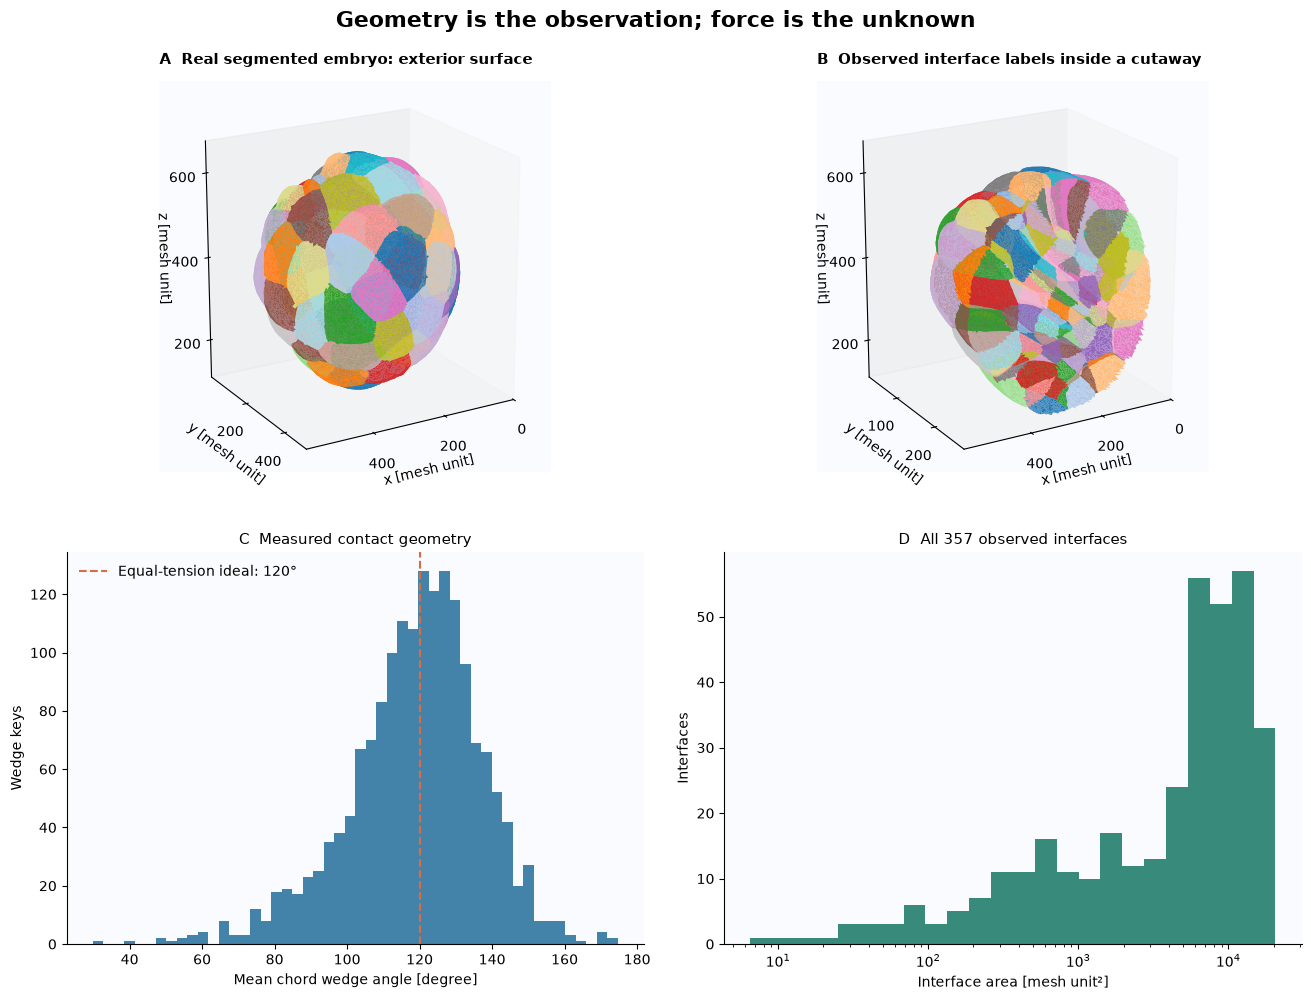

In [2]:
mesh=prepare_mesh(**obs)
geometry=junction_geometry(mesh)
D,V,interfaces,regions,areas=area_volume_operators(mesh)
data_model={'mesh':mesh,'geometry':geometry,'D':D,'V':V,'interfaces':interfaces,'cells':regions,'areas':areas}
print('Used geometry:',mesh.vertices.shape,mesh.triangles.shape)
print('Region labels:',regions)
print('Valid triple edges / malformed three-region edges:',len(geometry['valid_edges']),len(geometry['malformed_edges']))
print('All bounded-cell volumes positive:',bool(np.all(cell_volumes(mesh)[1][1:]>0)))
fig,numeric=vis.plot_observations(data_model)
show(fig,'figure01_observed_geometry',numeric)


## 3. Physics — force balance and explicit mesh derivatives

For interface areas $A_i$, cell volumes $V_c$, tensions $\gamma_i$, pressures $p_c$, and stacked vertex coordinates $\boldsymbol x$, the quasistatic Lagrangian is

$$\mathcal L=\sum_i\gamma_i A_i-\sum_{c>0}p_cV_c,\qquad D^{\mathsf T}\boldsymbol\gamma-V^{\mathsf T}\boldsymbol p\approx0.$$

Here $D$ has one row per interface area derivative, and $V$ hereafter denotes **cell rows only**, excluding exterior pressure; both have vertex-major x,y,z columns. A triangle with vertices $\boldsymbol a,\boldsymbol b,\boldsymbol c$ and outward unit normal $\boldsymbol n$ contributes

$$A=\tfrac12\| (\boldsymbol b-\boldsymbol a)\times(\boldsymbol c-\boldsymbol a)\|,
\qquad \nabla_{\boldsymbol a}A=\tfrac12\boldsymbol n\times(\boldsymbol c-\boldsymbol b),$$

$$V_{\triangle}=\tfrac16\boldsymbol a\cdot(\boldsymbol b\times\boldsymbol c),
\qquad\nabla_{\boldsymbol a}V_{\triangle}=\tfrac16\boldsymbol b\times\boldsymbol c.$$

The other vertex derivatives follow by cyclic permutation. Volume contributions have opposite signs for the two regions. These formulas are evaluated locally with NumPy and sparse scatter-add; no mesh-reconstruction or force-inference library is imported. Independent tests check regular-tetrahedron area/volume/pressure, translation, scaling, directional derivatives and label/winding equivalence.

On this noisy mesh, **zero vertex force is not attainable in general**. For fixed inferred tensions, the variational pressure optimum satisfies $VV^{\mathsf T}\boldsymbol p=VD^{\mathsf T}\boldsymbol\gamma$. A small normal-equation residual establishes that conditional optimum, not true tissue equilibrium.

In [3]:
G=(V[1:]@V[1:].T).toarray()
print('Pressure-system rank / unknown cells:',np.linalg.matrix_rank(G),len(regions)-1)
print('Pressure Gram condition number:',np.linalg.cond(G))


Pressure-system rank / unknown cells: 64 64
Pressure Gram condition number: 91.78183984946718


## 4. Method — junction inversion, then pressures

For ordered region labels $a<b<c$, let $\theta_a,\theta_b,\theta_c$ be arithmetic mean **chord** wedge angles inside those regions along a triple line. For $\boldsymbol\gamma_\ell=(\gamma_{ab},\gamma_{bc},\gamma_{ac})^{\mathsf T}$, scalar Young–Dupré balance uses

$$C_\ell=\begin{pmatrix}1&\cos\theta_b&\cos\theta_a\\\cos\theta_b&1&\cos\theta_c\\\cos\theta_a&\cos\theta_c&1\end{pmatrix},\qquad
\min_{\boldsymbol\gamma}\sum_\ell( L_\ell/L_{\mathrm{total}})^2\|C_\ell\boldsymbol\gamma_\ell\|^2,\quad \sum_i\gamma_i=357.$$

Here $L_\ell$ is junction length and $L_{\mathrm{total}}$ is total measured junction length. The original algorithm visits each geometric edge through its three incident half edges and appends each wedge twice. Its six-times arclength accounting cancels from this ratio and is retained for numeric parity. Angles are averaged by edge visits, not arclength.

A power-of-two gauge-row weight matches typical force-row norms; dense least squares is followed by exact homogeneous rescaling. The selected current upstream enforces the arithmetic gauge exactly; the paper's historical soft gauge affected overall scale. The pressure step evaluates the explicit area/volume Gram blocks and dense inverse. There is no optimization checkpoint, learned prior, generic domain solver or target-derived calibration.

The chord reader uses arccos in $[0,\pi]$ and can reflect a reflex wedge. Figure 5 retains its resulting angle-closure deviations. The selected estimate is conditional on this published measurement convention, rather than a claim that every noisy junction forms an ideal convex foam.

Complete fresh bound reconstruction seconds: 14.465342900002724


{
  "tensions_ncc": 1.0000000000000002,
  "tensions_nrmse": 8.015325328981584e-16,
  "pressures_ncc": 1.0000000000000002,
  "pressures_nrmse": 7.351816260942865e-16,
  "pressure_normal_equations_relative_l2": 1.4073086993879775e-13,
  "mean_tension_absolute_error": 0.0,
  "medium_pressure_absolute": 0.0
}


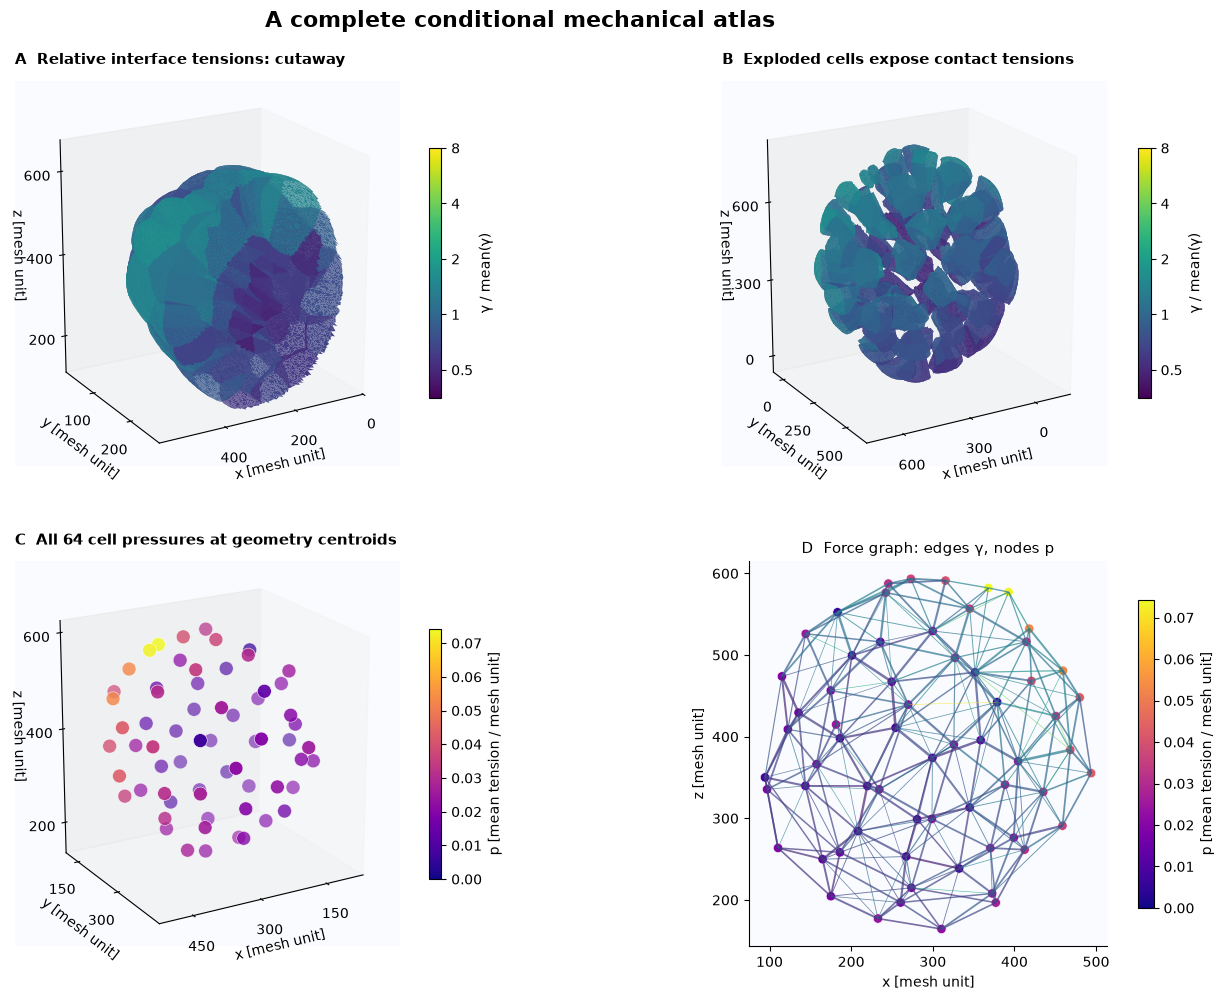

In [4]:
start=time.perf_counter()
fresh=reconstruct(obs)
reconstruction_seconds=time.perf_counter()-start
print('Complete fresh bound reconstruction seconds:',reconstruction_seconds)
out=ROOT/'output/reconstruction.npz';out.parent.mkdir(exist_ok=True)
np.savez_compressed(out,tensions=fresh['tensions'][None],pressures=fresh['pressures'][None])
spec=importlib.util.spec_from_file_location('review_force_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(out)
assert exit_code==0,report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(report['metrics'],indent=2))
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as d:author={k:d[k][0] for k in d.files}
fig,numeric=vis.plot_atlas(fresh);show(fig,'figure02_force_atlas',numeric)


**Figure 2:** both tension maps use the same logarithmic color scale; pressure has its own linear scale and units. Panel A clips geometry only for display. Panel B shifts each complete cell by 75% of its centroid's displacement from the embryo center, revealing internal contacts; these exploded display positions are not new measured coordinates. The force graph uses observed cell labels, with node pressure and edge tension; edge width indicates interface area. These are reconstructed forces on measured geometry, not measured force ground truth.

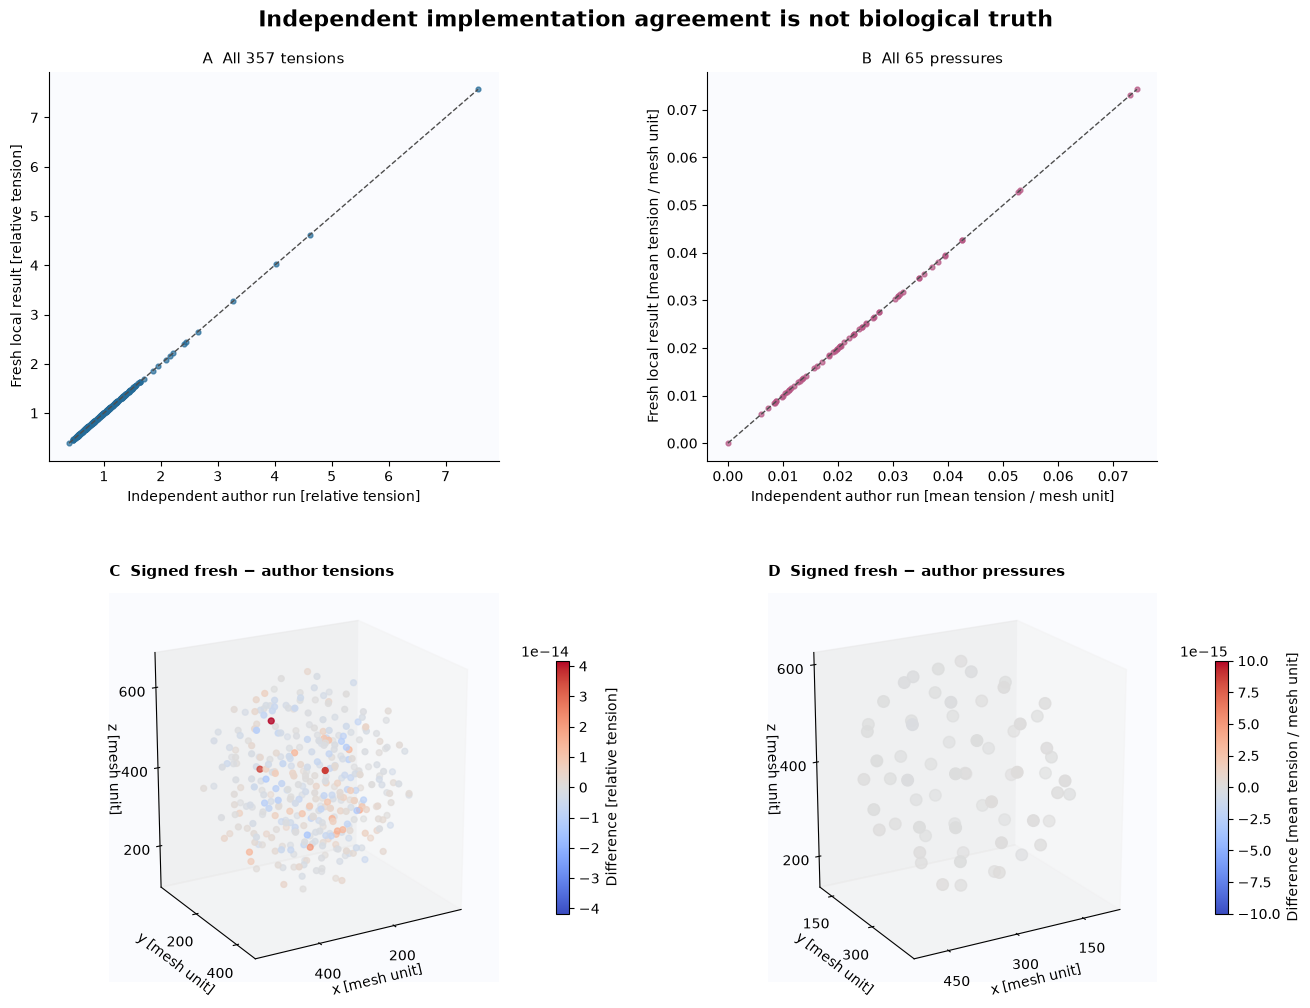

In [5]:
fig,numeric=vis.plot_parity(fresh,author);show(fig,'figure03_original_local_parity',numeric)


**Figure 3:** every interface and every region is compared. Spatial signed differences have symmetric limits centered on zero; no magnitude conversion, scale fit, component permutation or masked tail is used. The tight agreement verifies extraction. The nonzero acceptance limits were frozen **before local inverse implementation**, from an independent full original repeat, three LAPACK drivers in float64/float32, and output serialization; constant, zero and reversed controls failed. Neither bitwise repeatability nor reference agreement is evidence of biological accuracy.

## 5. Results — scientific comparisons and sensitivity

The supplementary paper compared Young–Dupré, projection, Lami, inverse Lami, log Lami and variational formulas, including line-length weighting and curvature versus variational pressure. We compute those families here on the **same full observed mesh**. The paper's variational **Gram** route and the current author's later **Operator** route are displayed separately: they minimize different noisy-data residuals. The Operator comparison retains its full explicit Householder elimination and least-squares solve; it is not substituted by the main estimator.

Log Lami's native gauge fixes geometric mean tension, whereas other displayed families fix arithmetic mean. For the figure alone its entire tension/pressure atlas is divided by its arithmetic mean, so common plots compare the same overall scale. Native outputs remain saved in numeric sources. All pressure-law fits use their actual computed curvature conventions and area weighting. Negative curvature-based pressures, if present, remain visible.

Published median errors on 47 simulated cell clusters were 10.1% for length-weighted Young–Dupré versus 10.8% without length weighting, and 12.0% for variational pressure versus 12.5% for weighted Laplace pressure. Those **historical simulated-truth errors are not metrics of this real specimen**. No force truth exists here, so the fresh comparisons report objective tradeoffs and conditional atlas changes instead.

All fresh formulation comparison seconds: 13.098559499994735
Independent original-versus-fresh comparison max-absolute errors:
{
  "young_dupre": {
    "tensions": 4.1744385725905886e-14,
    "pressures": 1.7694179454963432e-16
  },
  "projection": {
    "tensions": 4.529709940470639e-14,
    "pressures": 4.0245584642661925e-16
  },
  "lami": {
    "tensions": 5.1514348342607263e-14,
    "pressures": 1.8041124150158794e-16
  },
  "inverse_lami": {
    "tensions": 5.1514348342607263e-14,
    "pressures": 2.7755575615628914e-16
  },
  "log_lami": {
    "tensions": 8.43769498715119e-15,
    "pressures": 1.3877787807814457e-16
  },
  "variational_operator": {
    "tensions": 1.8207657603852567e-13,
    "pressures": 6.808789643208968e-16
  },
  "variational_gram": {
    "tensions": 4.3720582709738665e-13,
    "pressures": 4.9057979900624105e-15
  },
  "laplace": {
    "pressures": 1.6653345369377348e-16
  },
  "laplace_weighted_curvature": {
    "pressures": 1.734723475976807e-16
  }
}


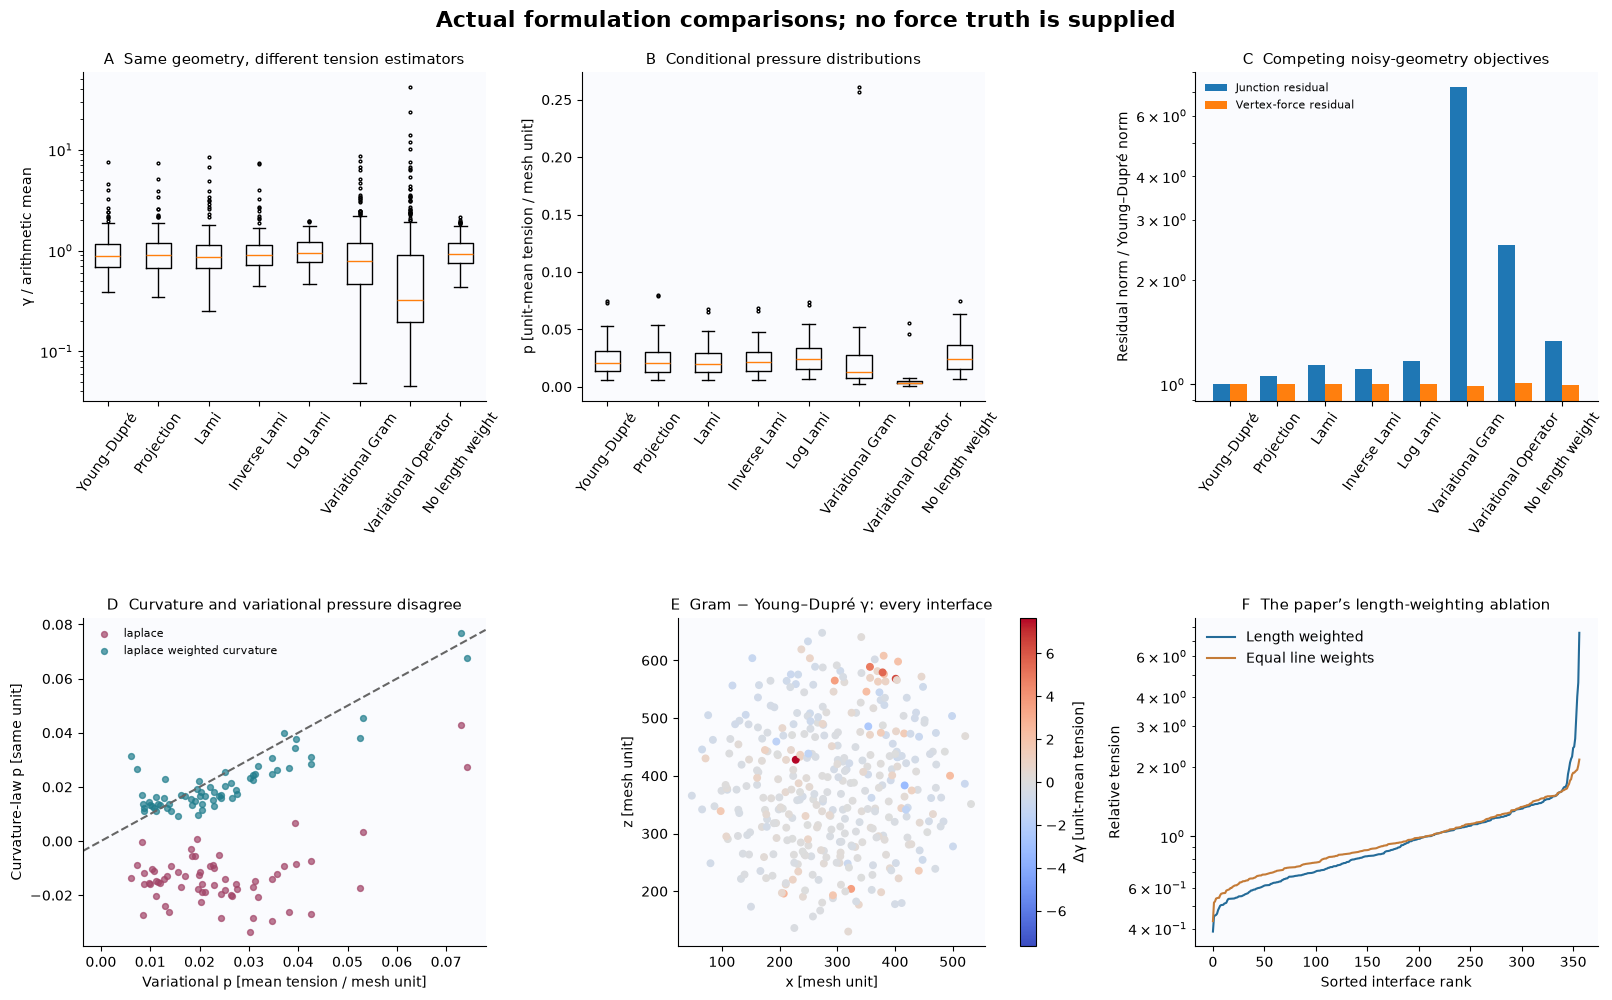

In [6]:
start=time.perf_counter()
methods=compare_formulations(fresh,include_operator=True)
print('All fresh formulation comparison seconds:',time.perf_counter()-start)
with np.load(ROOT/'notebooks/reference_outputs/original_formulations.npz',allow_pickle=False) as d:original_methods={k:d[k] for k in d.files}
mapping={'young_dupre':'YoungDupre','projection':'ProjectionYoungDupre','lami':'Lami','inverse_lami':'InvLami','log_lami':'LogLami','variational_operator':'Variational'}
comparison_errors={}
for local,source in mapping.items():
    comparison_errors[local]={key:float(np.max(abs(methods[local][key]-original_methods[source+'_'+key]))) for key in ['tensions','pressures']}
with np.load(ROOT/'notebooks/reference_outputs/original_gram.npz',allow_pickle=False) as d:
    comparison_errors['variational_gram']={key:float(np.max(abs(methods['variational_gram'][key]-d[key]))) for key in ['tensions','pressures']}
for local,source in [('laplace','Laplace'),('laplace_weighted_curvature','WeightedLaplace')]:
    comparison_errors[local]={'pressures':float(np.max(abs(methods[local]['pressures']-original_methods[source+'_pressures'])))}
print('Independent original-versus-fresh comparison max-absolute errors:')
print(json.dumps(comparison_errors,indent=2))
fig,numeric=vis.plot_comparisons(fresh,methods);show(fig,'figure04_formulation_comparisons',numeric)


**Figure 4:** all methods are freshly computed. A lower residual for one of the two objectives does not rank biological accuracy. Both curvature pressure variants weight interface equations by area; their difference is vertex-area weighting when averaging curvature. The length-weighting ablation preserves every other junction equation and gauge.

Next, perturb all measured coordinates independently with zero-mean Gaussian displacement. Standard deviations 0.1, 0.25 and 0.5 are in author mesh units. These are newly generated diagnostic perturbations of existing real geometry, **not author simulation data, a segmentation-noise calibration, posterior confidence intervals or new benchmark inputs**. Topology and the malformed-edge rule remain unchanged. Negative tensions are counted and retained.

[
  {
    "sigma": 0.1,
    "seed": 210,
    "runtime_seconds": 14.36076550000871,
    "nonpositive_tensions": 0
  },
  {
    "sigma": 0.25,
    "seed": 211,
    "runtime_seconds": 14.359214600000996,
    "nonpositive_tensions": 0
  },
  {
    "sigma": 0.5,
    "seed": 212,
    "runtime_seconds": 14.358003599991207,
    "nonpositive_tensions": 0
  }
]


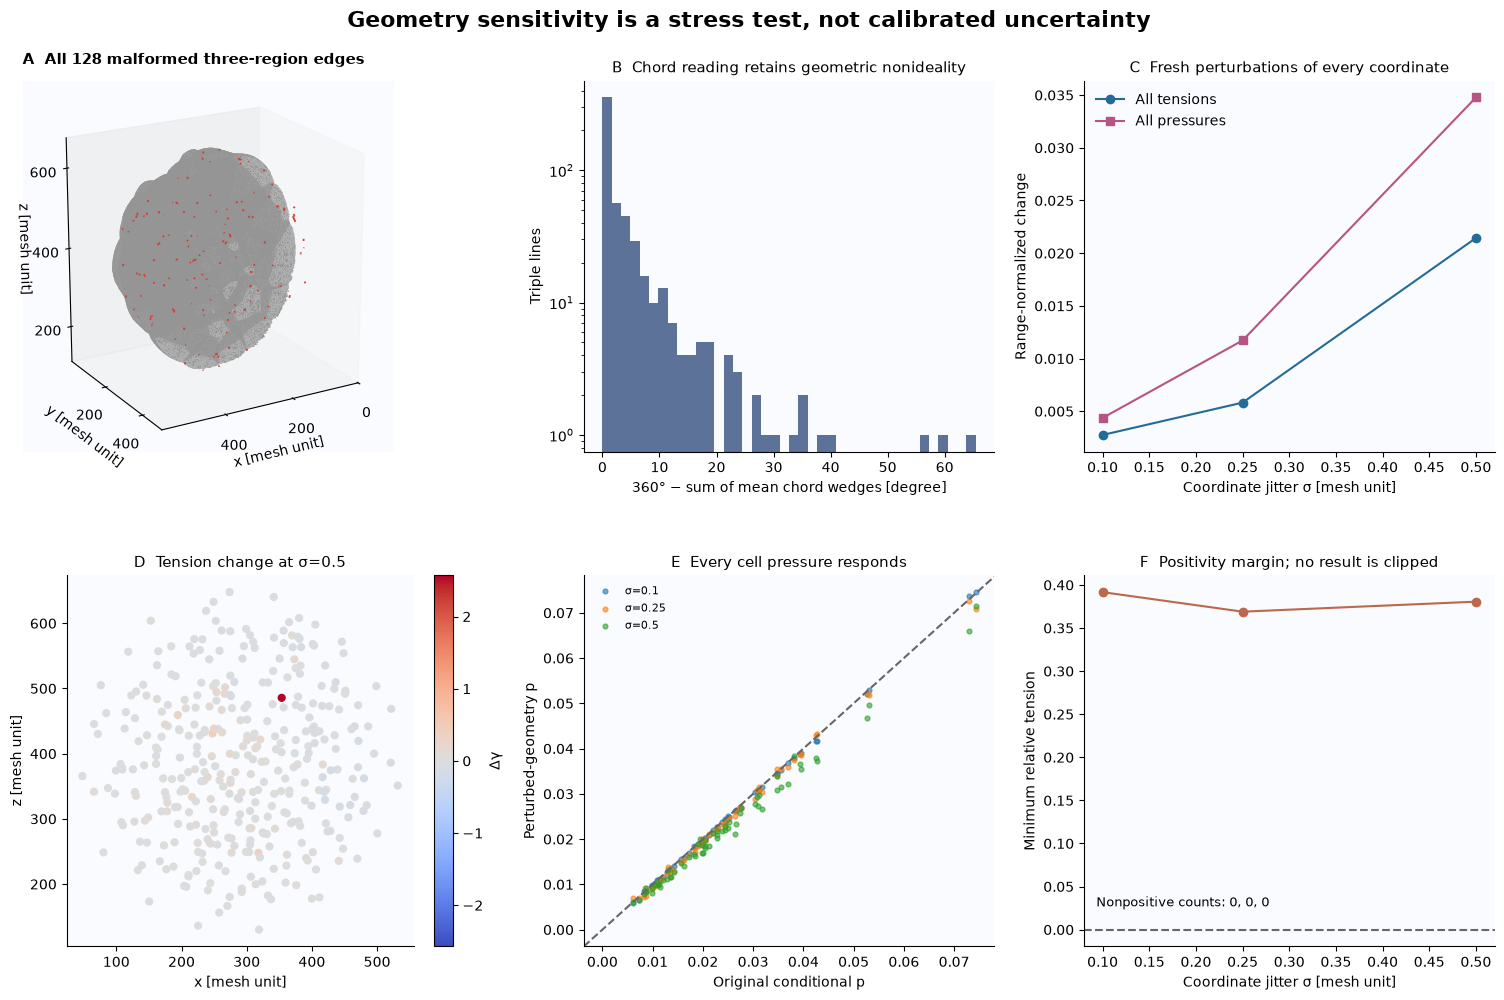

In [7]:
sigmas=[.1,.25,.5]
perturbed=[];perturbation_runs=[]
for i,sigma in enumerate(sigmas):
    start=time.perf_counter();value=reconstruct(perturb_geometry(obs,sigma,seed=210+i))
    perturbed.append(value);perturbation_runs.append({'sigma':sigma,'seed':210+i,'runtime_seconds':time.perf_counter()-start,'nonpositive_tensions':int(np.count_nonzero(value['tensions']<=0))})
print(json.dumps(perturbation_runs,indent=2))
fig,numeric=vis.plot_sensitivity(fresh,perturbed,sigmas);show(fig,'figure05_geometry_sensitivity',numeric)


**Figure 5:** the red segments are all 128 malformed three-region edges, shown against a display cutaway. They are not removed from the membrane-area or volume derivatives. Angle-closure deviations diagnose the selected chord reader and nonideal geometry. Jitter changes are assessed against the original conditional estimate, not a hypothetical force truth. The positivity-margin panel reports actual minima and nonpositive counts without clipping.

Finally, rescale every mesh coordinate by 0.5 and 2, run the entire inverse again, and change the tension gauge through a new solve. Geometry implies $D(s\boldsymbol x)=sD(\boldsymbol x)$ and $V(s\boldsymbol x)=s^2V(\boldsymbol x)$, so tensions stay unchanged and pressures scale as $1/s$. Refit the same full junction system with three general LAPACK drivers in each arithmetic precision. Frozen limits are shown for context; they are not selected from these fresh results.

[
  {
    "label": "gelsd float64",
    "tensions_nrmse": 0.0,
    "pressures_nrmse": 7.642089500998734e-17
  },
  {
    "label": "gelsd float32",
    "tensions_nrmse": 3.2075971744560826e-07,
    "pressures_nrmse": 3.486062180404539e-07
  },
  {
    "label": "gelss float64",
    "tensions_nrmse": 8.775353191691507e-16,
    "pressures_nrmse": 1.192282401326306e-15
  },
  {
    "label": "gelss float32",
    "tensions_nrmse": 4.769238432981546e-07,
    "pressures_nrmse": 4.6327052664136064e-07
  },
  {
    "label": "gelsy float64",
    "tensions_nrmse": 6.253411640047726e-16,
    "pressures_nrmse": 6.297334566356363e-16
  },
  {
    "label": "gelsy float32",
    "tensions_nrmse": 6.298808475455018e-08,
    "pressures_nrmse": 7.616805052707595e-08
  }
]


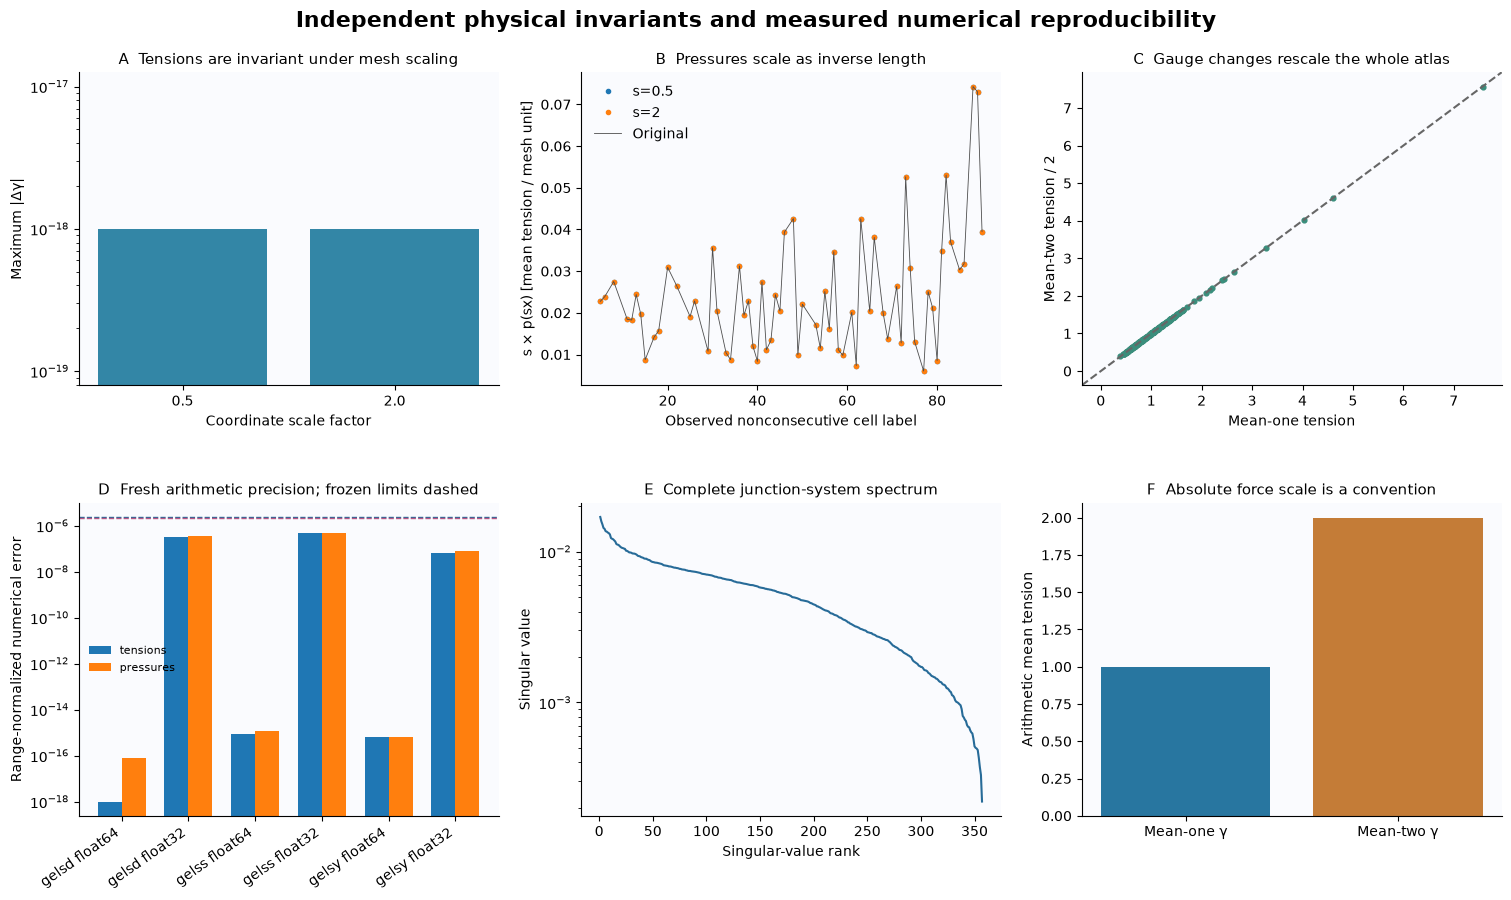

In [8]:
scales=[.5,2.]
scaled=[]
for scale in scales:
    scaled_obs={k:v.copy() for k,v in obs.items()};scaled_obs['vertices']*=scale
    scaled.append(reconstruct(scaled_obs))
gamma2=solve_tensions(fresh['M'],fresh['b'],mean_tension=2)
gauged={'tensions':gamma2,'pressures':solve_pressures(fresh['D'],fresh['V'],gamma2)}
P=fresh['M'][:-1];n=P.shape[1]
w=2.**np.round(np.log2(np.median(np.linalg.norm(P,axis=1))/np.sqrt(n)))
A=np.vstack([P,np.full((1,n),w)]);b=np.r_[np.zeros(len(P)),w*n]
Gp=(fresh['V'][1:]@fresh['V'][1:].T).toarray();Hp=(fresh['V'][1:]@fresh['D'].T).toarray()
precision=[]
for driver in ['gelsd','gelss','gelsy']:
    for dtype in ['float64','float32']:
        g=scipy.linalg.lstsq(A.astype(dtype),b.astype(dtype),lapack_driver=driver)[0].astype(float);g*=n/g.sum()
        p=np.r_[0.,scipy.linalg.solve(Gp.astype(dtype),(Hp@g).astype(dtype)).astype(float)]
        precision.append({'label':driver+' '+dtype,'tensions_nrmse':vis._metrics(g,fresh['tensions'])[0],'pressures_nrmse':vis._metrics(p,fresh['pressures'])[0]})
definition=json.loads((ROOT/'evaluation/metrics.json').read_text())
thresholds={k:{'nrmse_boundary':definition['thresholds'][k+'_nrmse']['boundary']} for k in ['tensions','pressures']}
print(json.dumps(precision,indent=2))
fig,numeric=vis.plot_scaling(fresh,scaled,scales,gauged,precision,thresholds)
show(fig,'figure06_scale_gauge_precision',numeric)


**Figure 6:** exact or sub-$10^{-18}$ numerical changes are displayed at a $10^{-18}$ plotting floor. Scale experiments and gauge experiments use new full solves, not manually rescaled pictures. The spectrum contains all junction-system singular values. This selected conditional inverse can be reproduced numerically even though coordinate perturbations and other valid force-balance estimators produce larger scientific differences.

## 6. Conclusion — what the atlas establishes

The complete real observed geometry yields a finite, spatially indexed mechanical atlas under the stated tension and pressure gauges. The fresh implementation reproduces independently captured original stages and all task-relevant formulation comparisons, including the difficult curvature pressure routes. The standalone Judge scores every required output and checks pressure normal equations separately.

The atlas is **method-defined**, not independent biological truth. The mesh has uncalibrated metric scale, retained topological defects and nonideal chord geometry. Other estimators and diagnostic coordinate perturbations show consequential uncertainty. These limitations remain visible instead of being absorbed into loose reference tolerances or removed by a target-dependent mask.

In [9]:
summary={'environment':environment,'raw_sha256':raw_hash,'reconstruction_seconds':reconstruction_seconds,'judge_status':report['status'],'metrics':report['metrics'],'original_comparison_maxabs':comparison_errors,'perturbation_runs':perturbation_runs,'precision_runs':precision,'coordinate_scales':scales,'reference_role':'independent author-method result, not biological force truth'}
refs=ROOT/'notebooks/reference_outputs'
(refs/'fresh_run.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
pressure_moments=fresh['V'][1:]@(fresh['D'].T@fresh['tensions']-fresh['V'].T@fresh['pressures'])
np.savez_compressed(refs/'fresh_diagnostics.npz',weighted_junction_residual=fresh['M'][:-1]@fresh['tensions'],pressure_normal_moments=pressure_moments,interface_labels=fresh['interfaces'],cell_labels=fresh['cells'])
if EXPORT is not None:
    (EXPORT/'experiment_metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
display(Markdown(f"**Fresh complete reconstruction:** {reconstruction_seconds:.2f} s; Judge `{report['status']}`. All 357 tensions and 65 region pressures are evaluated. No independent biological force truth or absolute force calibration is claimed."))


**Fresh complete reconstruction:** 14.47 s; Judge `pass`. All 357 tensions and 65 region pressures are evaluated. No independent biological force truth or absolute force calibration is claimed.